# Monthly CL1–CL2 spread model

Alan and Ronan. Tasks 1–3: data and repo setup, evaluation and test run, stationarity and data checks.

Spread $S_t = CL1_t - CL2_t$ in \$/bbl at month-end ($S > 0$ backwardation, $S < 0$ contango).
Target: $\Delta S_{t+1} = S_{t+1} - S_t$. Everything reads `data/clean/oil_monthly_clean.csv`, where row $t$ holds what was known at the end of month $t$.

In [1]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, adfuller, kpss, zivot_andrews

warnings.simplefilter("ignore", InterpolationWarning)
warnings.simplefilter("ignore", FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "clean" / "oil_monthly_clean.csv").exists())
RAW = REPO / "data" / "raw" / "Oil Data.xlsx"
CLEAN_MONTHLY = REPO / "data" / "clean" / "oil_monthly_clean.csv"
CLEAN_DAILY = REPO / "data" / "clean" / "oil_daily_cl1_cl2.csv"
RESULTS = REPO / "data" / "results" / "Alan&Ronan"
RESULTS.mkdir(parents=True, exist_ok=True)

VALID = ("2005-01", "2014-12")
TEST = ("2015-01", "2024-06")
PRE_TEST_END = "2014-12-31"     # stationarity decisions use data up to here only

BAND_K = 1.0
ARMA_MAX = 3
ARMA_IC = "bic"
MIN_TRAIN = 30

## 1. Data and repo setup

### 1.1 Monthly clean file

In [2]:
monthly = pd.read_csv(CLEAN_MONTHLY, parse_dates=["date"])
assert monthly["date"].is_unique and monthly["date"].dt.is_month_end.all()
assert pd.DatetimeIndex(monthly["date"]).equals(
    pd.date_range(monthly["date"].min(), monthly["date"].max(), freq="ME")), "missing or extra month"
assert (monthly["cl1"] > 0).all() and (monthly["cl2"] > 0).all()
print(f"{len(monthly)} month-ends, {monthly['date'].min():%Y-%m} to {monthly['date'].max():%Y-%m}")

355 month-ends, 1994-12 to 2024-06


In [3]:
def load_monthly(last_target_month):
    """Rows up to target month `last_target_month` ('YYYY-MM'); later rows are dropped before anything is fitted."""
    df = monthly.copy()
    df["S"] = df["cl1"] - df["cl2"]
    df["y"] = df["S"].shift(-1) - df["S"]
    df["ip_growth"] = 100 * df["ip_index"].pct_change(fill_method=None)   # ip_index already lagged one month
    df = df[df["target_month"].notna() & (df["target_month"] <= last_target_month)]
    return df.reset_index(drop=True)

### 1.2 Shared daily CL1/CL2 file

Needed for the weekly evidence and for a trading rule on contracts that can actually be held.
Source: sheet `Industry_D`, prices unchanged; rows with no date or no CL1/CL2 (trailing Brent-only rows) dropped.

| Column | Meaning |
|---|---|
| `spread` | CL1 − CL2, \$/bbl |
| `cl1_last_trading_day` | 1 on the estimated last trading day of the CL1 contract |
| `days_to_cl1_expiry` | trading days until that day |
| `cl1_rolled` | 1 on the first day CL1 is the next contract; the spread change that day compares two contract pairs and is not a P&L |

Expiry (NYMEX WTI): 3 business days before the 25th of the month, 4 if the 25th is not a business day. The file's own trading days stand in for the exchange calendar, so a date can be a day off around weekday holidays.

In [4]:
daily = pd.read_excel(RAW, sheet_name="Industry_D")
daily["Date"] = pd.to_datetime(daily["Date"], errors="coerce")
daily = (daily.dropna(subset=["Date", "CL1", "CL2"]).sort_values("Date")
              .rename(columns={"Date": "date", "CL1": "cl1", "CL2": "cl2"})[["date", "cl1", "cl2"]]
              .reset_index(drop=True))
assert daily["date"].is_unique
daily["spread"] = (daily["cl1"] - daily["cl2"]).round(4)

days = pd.DatetimeIndex(daily["date"])
expiries = []
for year in range(days[0].year, days[-1].year + 1):
    for month in range(1, 13):
        d25 = pd.Timestamp(year, month, 25)
        before = days[(days < d25) & (days >= d25 - pd.Timedelta(days=20))]
        k = 3 if d25 in days else 4
        if len(before) >= k and d25 <= days[-1] + pd.Timedelta(days=10):
            expiries.append(before[-k])
expiries = pd.DatetimeIndex(expiries)

pos = np.arange(len(days))
exp_pos = np.searchsorted(days, expiries)
nxt = np.searchsorted(exp_pos, pos, side="left")
daily["cl1_last_trading_day"] = np.isin(pos, exp_pos).astype(int)
daily["days_to_cl1_expiry"] = pd.array(
    np.where(nxt < len(exp_pos), exp_pos[nxt.clip(max=len(exp_pos) - 1)] - pos, np.nan), dtype="Int64")
daily["cl1_rolled"] = daily["cl1_last_trading_day"].shift(1, fill_value=0)

last = daily.groupby(daily["date"].dt.to_period("M"))[["cl1", "cl2"]].last()
chk = monthly.set_index(monthly["date"].dt.to_period("M"))[["cl1", "cl2"]].join(last, rsuffix="_d")
assert chk[["cl1_d", "cl2_d"]].notna().all().all(), "a month in the monthly file has no daily prices"
gap = (chk[["cl1", "cl2"]].values - chk[["cl1_d", "cl2_d"]].values).__abs__().max()
assert gap < 1e-9, "daily month-end prices do not match the monthly clean file"

chg = daily["spread"].diff().abs()
daily.to_csv(CLEAN_DAILY, index=False, date_format="%Y-%m-%d")
print(f"{len(daily)} trading days, {daily['date'].min():%Y-%m-%d} to {daily['date'].max():%Y-%m-%d}, {len(expiries)} expiries")
print(f"Month-end prices match the monthly file (max gap {gap:.2g})")
print(f"Median |daily spread change|: {chg[daily.cl1_rolled == 1].median():.3f} on roll days, "
      f"{chg[daily.cl1_rolled == 0].median():.3f} on other days")
print("Wrote", CLEAN_DAILY.relative_to(REPO))
daily.loc[daily["cl1"] <= 0, ["date", "cl1", "cl2", "spread", "days_to_cl1_expiry"]]

8692 trading days, 1990-01-02 to 2024-07-30, 415 expiries
Month-end prices match the monthly file (max gap 0)
Median |daily spread change|: 0.250 on roll days, 0.040 on other days
Wrote data\clean\oil_daily_cl1_cl2.csv


C:\Users\mphil\AppData\Local\Temp\ipykernel_31504\3650387064.py:29: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  chk = monthly.set_index(monthly["date"].dt.to_period("M"))[["cl1", "cl2"]].join(last, rsuffix="_d")


,date,cl1,cl2,spread,days_to_cl1_expiry
7613,2020-04-20,-37.630,20.430,-58.060,1


The only non-positive price in the daily file is the −37.63 CL1 settlement on 20 April 2020, the day before the May contract expired. It is kept as traded. It never reaches the monthly file (30 April CL1 = 18.84), but a daily trading rule that holds CL1 into expiry would see it.

### 1.3 Outliers in the target
Flagged, not removed. A month is flagged when the spread change is more than 4 sd from its mean, both taken from the training months (target months to Dec 2004). Rows are forecast origins; the move happens the following month. Dummies are a modelling choice and are tested in the diagnostics and robustness tasks, each tied to a named event (Diagnostics lecture: a dummy needs a reason).

In [5]:
OUTLIER_Z = 4
EVENTS = {
    "2008-12": "financial crisis: demand collapse, storage filling, deep contango",
    "2009-02": "contango unwinds from its January 2009 extreme",
    "2010-04": "Cushing stocks high, front-month weakness",
    "2015-02": "2014-16 OPEC price war: oversupply widens contango",
    "2020-03": "COVID demand collapse and OPEC+ breakdown",
    "2020-05": "rebound after the negative-price episode",
}
tgt = load_monthly(TEST[1])
train = tgt["target_month"] <= "2004-12"
mu, sd = tgt.loc[train, "y"].mean(), tgt.loc[train, "y"].std()
tgt["y_z"] = (tgt["y"] - mu) / sd
outliers = tgt.loc[tgt["y_z"].abs() > OUTLIER_Z, ["target_month", "S", "y", "y_z"]].rename(
    columns={"S": "spread at origin", "y": "change next month"})
outliers["event"] = outliers["target_month"].map(EVENTS)
assert outliers["event"].notna().all(), "new outlier month without an explanation"
outliers.to_csv(RESULTS / "target_outliers.csv", index=False)
print(f"Training mean {mu:.3f}, sd {sd:.3f} $/bbl")
outliers.set_index("target_month")

Training mean -0.002, sd 0.391 $/bbl


,spread at origin,change next month,y_z,event
target_month,,,,
2008-12,-1.390,-2.600,-6.645,"financial crisis: demand collapse, storage fil..."
2009-02,-4.450,2.320,5.939,contango unwinds from its January 2009 extreme
2010-04,-0.420,-1.790,-4.574,"Cushing stocks high, front-month weakness"
2015-02,-0.750,-1.630,-4.164,2014-16 OPEC price war: oversupply widens cont...
2020-03,-0.180,-3.850,-9.843,COVID demand collapse and OPEC+ breakdown
2020-05,-3.010,2.660,6.809,rebound after the negative-price episode


## 2. Evaluation and test run

All forecasts are one step ahead, expanding window, re-estimated every month, using rows before the origin only.

| Model | Forecast of $\Delta S_{t+1}$ |
|---|---|
| No change | 0 |
| Plain mean reversion | $a + bS_t$ |
| ARMA | ARMA(p,q) on $S$ (levels, see Section 3), $p,q \le 3$, order by BIC on data before the window, Ljung-Box on residuals |
| **Band mean reversion (final)** | $a + b_{in} S_t \cdot inside + b_{out} S_t \cdot outside + d \cdot outside$ |

*outside* = $S_t$ beyond mean ± 1 sd of past spreads. Tests: Clark–West (one-sided, right for nested models) and Diebold–Mariano with the Harvey–Leybourne–Newbold correction (two-sided, conservative for nested models).

In [6]:
def _ols_predict(X, y, i):
    Xi, yi = X[:i], y[:i]
    ok = ~np.isnan(Xi).any(axis=1) & ~np.isnan(yi)
    if ok.sum() < MIN_TRAIN or np.isnan(X[i]).any():
        return np.nan
    beta, *_ = np.linalg.lstsq(Xi[ok], yi[ok], rcond=None)
    return float(X[i] @ beta)


def forecast_ar(df, origins):
    X = np.column_stack([np.ones(len(df)), df["S"].values])
    return np.array([_ols_predict(X, df["y"].values, i) for i in origins])


def band_at(df, i, k=BAND_K):
    past = df["S"].values[:i]
    return past.mean() - k * past.std(), past.mean() + k * past.std()


def band_design(df, i, k=BAND_K):
    S = df["S"].values
    lo, hi = band_at(df, i, k)
    out = (S < lo) | (S > hi)
    return np.column_stack([np.ones(len(df)), S * ~out, S * out, out.astype(float)]), out


def forecast_band(df, origins, k=BAND_K):
    f, flag, lo_hi = [], [], []
    for i in origins:
        X, out = band_design(df, i, k)
        f.append(_ols_predict(X, df["y"].values, i))
        flag.append(bool(out[i]))
        lo_hi.append(band_at(df, i, k))
    return np.array(f), np.array(flag), np.array(lo_hi)


def select_arma_order(S):
    rows = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for p in range(ARMA_MAX + 1):
            for q in range(ARMA_MAX + 1):
                try:
                    m = ARIMA(S, order=(p, 0, q), trend="c").fit()
                    lb = acorr_ljungbox(m.resid, lags=[12], model_df=p + q)
                    rows.append({"p": p, "q": q, "aic": m.aic, "bic": m.bic,
                                 "ljung_box_p_12": float(lb["lb_pvalue"].iloc[0])})
                except Exception:
                    pass
    return pd.DataFrame(rows)


def forecast_arma(df, origins, order):
    S = df["S"].values
    f = []
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        for i in origins:
            m = ARIMA(S[: i + 1], order=(order[0], 0, order[1]), trend="c").fit()
            f.append(float(m.forecast(1)[0]) - S[i])
    return np.array(f)


def clark_west(y, f_bench, f_model):
    adj = (y - f_bench) ** 2 - ((y - f_model) ** 2 - (f_bench - f_model) ** 2)
    t = adj.mean() / (adj.std(ddof=1) / np.sqrt(len(adj)))
    return t, 1 - stats.norm.cdf(t)


def diebold_mariano(y, f_a, f_b):
    """Positive statistic: b is better."""
    d = (y - f_a) ** 2 - (y - f_b) ** 2
    n = len(d)
    dm = d.mean() / np.sqrt(d.var(ddof=0) / n) * np.sqrt((n - 1) / n)
    return dm, 2 * (1 - stats.t.cdf(abs(dm), n - 1))


def oos_r2(y, f_model, f_bench):
    return 1 - ((y - f_model) ** 2).sum() / ((y - f_bench) ** 2).sum()


def evaluate(df, first_month, last_month):
    in_win = (df["target_month"] >= first_month) & (df["target_month"] <= last_month)
    origins = np.where(in_win)[0]
    y = df["y"].values[origins]

    arma_table = select_arma_order(df["S"].values[: origins[0] + 1])
    best = arma_table.sort_values(ARMA_IC).iloc[0]
    order = (int(best.p), int(best.q))

    f_band, outside, bands = forecast_band(df, origins)
    fc = pd.DataFrame({
        "month": df["target_month"].values[origins],
        "origin": df["date"].dt.strftime("%Y-%m").values[origins],
        "spread_at_origin": df["S"].values[origins],
        "actual_spread": df["S"].values[origins] + y,
        "actual_change": y,
        "pred_no_change": 0.0,
        "pred_ar": forecast_ar(df, origins),
        "pred_arma": forecast_arma(df, origins, order),
        "pred_band": f_band,
        "outside_band": outside.astype(int),
        "band_lower": bands[:, 0],
        "band_upper": bands[:, 1],
    })

    zero = fc["pred_no_change"].values
    names = {"pred_no_change": "No change", "pred_ar": "Plain mean reversion",
             "pred_arma": f"ARMA{order} by {ARMA_IC.upper()}", "pred_band": "Band mean reversion (final)"}
    rows = []
    for col, name in names.items():
        f = fc[col].values
        e = y - f
        row = {"model": name, "n": len(y), "rmse": np.sqrt((e ** 2).mean()), "mae": np.abs(e).mean()}
        if col != "pred_no_change":
            call = (f != 0) & (y != 0)
            row["oos_r2_vs_no_change"] = oos_r2(y, f, zero)
            row["oos_r2_vs_ar"] = oos_r2(y, f, fc["pred_ar"].values)
            row["oos_r2_vs_arma"] = oos_r2(y, f, fc["pred_arma"].values)
            row["hit_rate"] = (np.sign(f[call]) == np.sign(y[call])).mean()
            row["cw_t_vs_no_change"], row["cw_p_vs_no_change"] = clark_west(y, zero, f)
            row["dm_t_vs_no_change"], row["dm_p_vs_no_change"] = diebold_mariano(y, zero, f)
        if col == "pred_band":
            row["cw_t_vs_ar"], row["cw_p_vs_ar"] = clark_west(y, fc["pred_ar"].values, f)
            row["dm_t_vs_ar"], row["dm_p_vs_ar"] = diebold_mariano(y, fc["pred_ar"].values, f)
        rows.append(row)

    o = outside
    if o.sum() > 1:
        f = f_band[o]
        rows.append({"model": "Final model, outside-band months only", "n": int(o.sum()),
                     "rmse": np.sqrt(((y[o] - f) ** 2).mean()), "mae": np.abs(y[o] - f).mean(),
                     "oos_r2_vs_no_change": oos_r2(y[o], f, 0 * f),
                     "hit_rate": (np.sign(f) == np.sign(y[o]))[y[o] != 0].mean()})
    return fc, pd.DataFrame(rows), arma_table


def save(fc, metrics, arma_table, label):
    fc.to_csv(RESULTS / f"forecasts_{label}.csv", index=False)
    metrics.to_csv(RESULTS / f"metrics_{label}.csv", index=False)
    arma_table.to_csv(RESULTS / f"arma_order_{label}.csv", index=False)


def charts(fc, label):
    x = pd.to_datetime(fc["month"])
    y = fc["actual_change"].values
    fig, ax = plt.subplots(figsize=(9, 4))
    for col, name in [("pred_band", "Band mean reversion (final)"),
                      ("pred_ar", "Plain mean reversion"), ("pred_arma", "ARMA")]:
        ax.plot(x, np.cumsum(y ** 2 - (y - fc[col].values) ** 2), label=name)
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Cumulative squared-error gain over no-change ({label})")
    ax.set_ylabel("($/bbl)$^2$, above zero = beating no-change")
    ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(RESULTS / f"cumulative_sse_{label}.png", dpi=300); plt.show()

    fig, ax = plt.subplots(figsize=(9, 4))
    xo = pd.to_datetime(fc["origin"])
    ax.plot(xo, fc["spread_at_origin"], color="black", lw=1, label="CL1 − CL2 spread")
    ax.fill_between(xo, fc["band_lower"], fc["band_upper"], alpha=0.2, label="Band (mean ± 1 sd, past data)")
    o = fc["outside_band"] == 1
    ax.scatter(xo[o], fc["spread_at_origin"][o], s=14, color="tab:red", zorder=3, label="Outside band")
    ax.set_title(f"Spread and band at each forecast origin ({label})")
    ax.set_ylabel("$/bbl (above zero = backwardation)")
    ax.legend(frameon=False)
    fig.tight_layout(); fig.savefig(RESULTS / f"spread_band_{label}.png", dpi=300); plt.show()

### 2.1 Fit on data to December 2014
The slopes on $S_t$ come from a Dickey–Fuller type regression ($\Delta S$ on $S_{t-1}$), so their t-statistics are compared with Dickey–Fuller critical values (−2.86 at 5%, −3.43 at 1%), not the normal table.

In [7]:
pre = load_monthly(VALID[1])
lo, hi = band_at(pre, len(pre))
out = (pre["S"] < lo) | (pre["S"] > hi)
X = pd.DataFrame({"const": 1.0, "b_in": pre["S"] * ~out, "b_out": pre["S"] * out, "d": out.astype(float)})
fit = sm.OLS(pre["y"], X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
wald = fit.t_test("b_in - b_out = 0")
print(f"Band {lo:.2f} to {hi:.2f} $/bbl, {out.mean():.0%} of months outside. Newey-West (3 lags).")
print(f"Wald test b_in = b_out: p = {float(wald.pvalue):.4f}")
pd.DataFrame({"coef": fit.params, "t": fit.tvalues, "p": fit.pvalues})

Band -0.96 to 0.68 $/bbl, 28% of months outside. Newey-West (3 lags).
Wald test b_in = b_out: p = 0.0001


,coef,t,p
const,0.005,0.206,0.837
b_in,0.142,1.932,0.053
b_out,-0.250,-4.615,0.000
d,-0.068,-0.929,0.353


### 2.2 Validation (target months Jan 2005 – Dec 2014)

In [8]:
df_val = load_monthly(VALID[1])
fc_val, metrics_val, arma_val = evaluate(df_val, *VALID)
save(fc_val, metrics_val, arma_val, "validation")
print("ARMA orders by BIC, data before the window:")
display(arma_val.sort_values(ARMA_IC).head())
metrics_val

ARMA orders by BIC, data before the window:


,p,q,aic,bic,ljung_box_p_12
8,2,0,94.114,105.297,0.697
5,1,1,94.678,105.861,0.611
4,1,0,98.176,106.563,0.180
9,2,1,96.100,110.079,0.607
12,3,0,96.101,110.080,0.608


,model,n,rmse,mae,oos_r2_vs_no_change,oos_r2_vs_ar,oos_r2_vs_arma,hit_rate,cw_t_vs_no_change,cw_p_vs_no_change,dm_t_vs_no_change,dm_p_vs_no_change,cw_t_vs_ar,cw_p_vs_ar,dm_t_vs_ar,dm_p_vs_ar
0,No change,120,0.581,0.393,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Plain mean reversion,120,0.576,0.386,0.018,0.000,0.027,0.575,1.562,0.059,0.250,0.803,NaN,NaN,NaN,NaN
2,"ARMA(2, 0) by BIC",120,0.584,0.391,-0.009,-0.028,0.000,0.558,1.167,0.122,-0.115,0.908,NaN,NaN,NaN,NaN
3,Band mean reversion (final),120,0.561,0.384,0.068,0.051,0.077,0.542,2.379,0.009,1.232,0.220,2.684,0.004,1.659,0.100
4,"Final model, outside-band months only",54,0.665,0.484,0.102,NaN,NaN,0.648,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


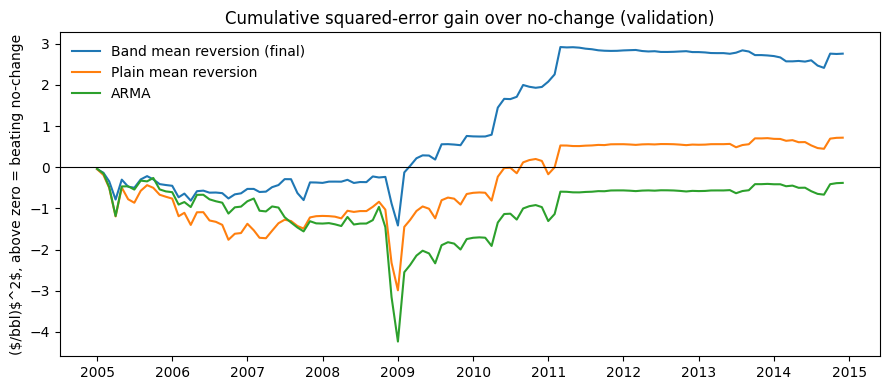

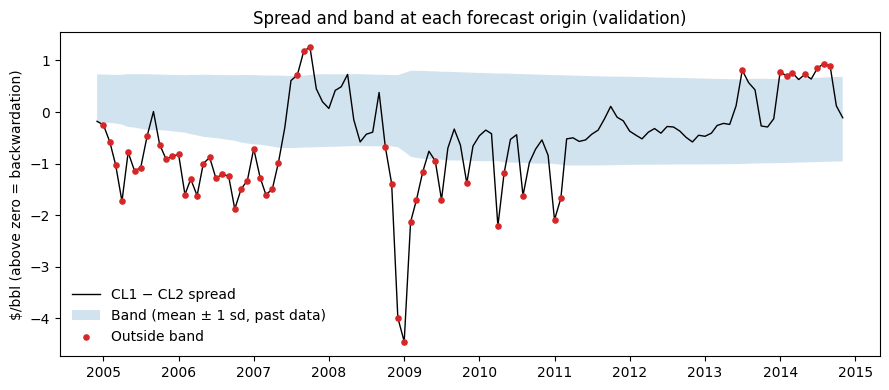

In [9]:
charts(fc_val, "validation")

### 2.3 Test run (target months Jan 2015 – Jun 2024)
Specification frozen before this window was opened (commit `f963e99`). The window is run once: if saved test forecasts exist, this cell reruns without saving and checks they match.

In [10]:
saved = RESULTS / "forecasts_test.csv"
df_test = load_monthly(TEST[1])
fc_test, metrics_test, arma_test = evaluate(df_test, *TEST)
if saved.exists():
    old = pd.read_csv(saved)
    cols = ["actual_change", "pred_ar", "pred_arma", "pred_band"]
    assert np.allclose(old[cols].values, fc_test[cols].values, atol=1e-6), "test forecasts do not reproduce"
    print("Saved test forecasts reproduced.")
else:
    save(fc_test, metrics_test, arma_test, "test")
    print("Test window run and saved.")
metrics_test

Saved test forecasts reproduced.


,model,n,rmse,mae,oos_r2_vs_no_change,oos_r2_vs_ar,oos_r2_vs_arma,hit_rate,cw_t_vs_no_change,cw_p_vs_no_change,dm_t_vs_no_change,dm_p_vs_no_change,cw_t_vs_ar,cw_p_vs_ar,dm_t_vs_ar,dm_p_vs_ar
0,No change,114,0.678,0.397,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Plain mean reversion,114,0.641,0.373,0.105,0.000,-0.001,0.562,2.277,0.011,1.502,0.136,NaN,NaN,NaN,NaN
2,"ARMA(1, 0) by BIC",114,0.641,0.373,0.106,0.001,0.000,0.562,2.280,0.011,1.495,0.138,NaN,NaN,NaN,NaN
3,Band mean reversion (final),114,0.622,0.368,0.157,0.058,0.057,0.562,2.748,0.003,1.836,0.069,2.621,0.004,1.736,0.085
4,"Final model, outside-band months only",26,0.724,0.553,0.366,NaN,NaN,0.769,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


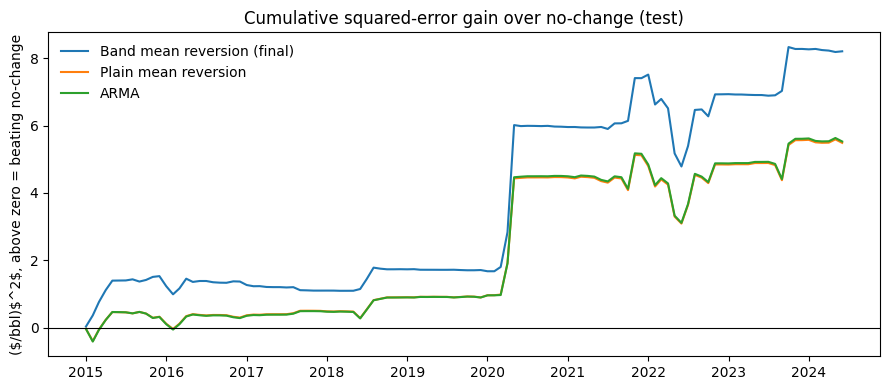

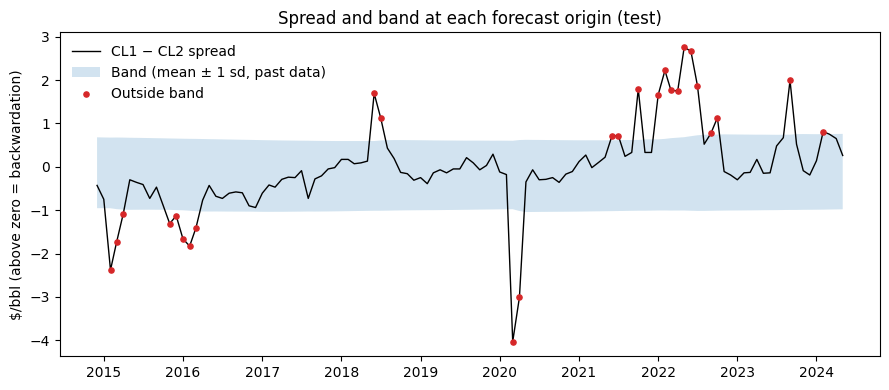

In [11]:
charts(fc_test, "test")

In [12]:
o = fc_test.assign(year=fc_test["month"].str[:4].astype(int))
sub = {"without 2020": o[o.year != 2020], "2015-19": o[o.year <= 2019], "2020-24": o[o.year >= 2020]}
pd.Series({k: oos_r2(v["actual_change"], v["pred_band"], 0) for k, v in sub.items()},
          name="band OOS R² vs no change").to_frame()

,band OOS R² vs no change
without 2020,0.136
2015-19,0.162
2020-24,0.155


## 3. Stationarity and data checks

Brent, Total Open Interest and the weekly sheets are not in the clean file (see the README), so they are not tested. `comm_long`/`comm_short` are labelled "commercial" in the workbook but probably cover all reporting traders.

Method, following the Unit Roots and ARMA lectures:

- **ADF** (H0 unit root). Constant only for series without a trend (spread, changes, rates, VIX); constant + trend for trending log levels. At most 12 lags (monthly data), chosen by BIC. Statistic compared with Fuller (1976) 5% values: −2.86 (constant), −3.41 (constant + trend).
- **KPSS** (H0 stationary), same deterministic terms, 5% critical value.
- **Decision** (Unit Roots slide 33): ADF rejects and KPSS does not → stationary; ADF does not and KPSS does → unit root; both reject → conflict; neither → inconclusive.
- **ACF** up to 12 lags with the ±1.96/√T band, Ljung-Box at lag 12. A unit root shows as an ACF that stays near 1.
- **Transformation**: log difference ×100 for positive prices, indices and quantities; plain difference for the spread, rates, VIX and `cpi_yoy` (can be zero or negative; differencing `cpi_yoy` is the second-difference check for CPI).
- Main sample: data to Dec 2014, so the test window plays no part. Full sample as a robustness check.

In [13]:
ADF_CV = {"c": -2.86, "ct": -3.41}
VERDICT = {(True, False): "stationary", (False, True): "unit root", (True, True): "conflict", (False, False): "inconclusive"}


def unit_root_tests(x, reg):
    x = x.dropna()
    a = adfuller(x, maxlag=12, regression=reg, autolag="BIC")
    k = kpss(x, regression=reg, nlags="auto")
    r = acf(x, nlags=12)
    return {"T": len(x), "ADF": a[0], "ADF lags": a[2], "ADF p": a[1], "KPSS": k[0], "KPSS 5% cv": k[3]["5%"],
            "ACF 1": r[1], "ACF 12": r[12], "LB p (12)": acorr_ljungbox(x, lags=[12])["lb_pvalue"].iloc[0],
            "verdict": VERDICT[(a[0] < ADF_CV[reg], k[0] > k[3]["5%"])]}


m = monthly.set_index("date")
SERIES = {   # name: (level, kind)  log = positive trending level, diff = can be <= 0, ret = already a change
    "spread S": (m["cl1"] - m["cl2"], "diff"), "CL1 price": (m["cl1"], "log"),
    "crack_321": (m["crack_321"], "diff"), "bdi": (m["bdi"], "log"), "production": (m["production"], "log"),
    "inventories": (m["inventories"], "log"), "rig_count": (m["rig_count"], "log"),
    "comm_long": (m["comm_long"], "log"), "comm_short": (m["comm_short"], "log"),
    "net commercial": (m["comm_long"] - m["comm_short"], "diff"),
    "cpi_yoy": (m["cpi_yoy"], "diff"), "IP": (m["ip_index"], "log"),
    "y3m": (m["y3m"], "diff"), "y10y": (m["y10y"], "diff"), "term spread": (m["y10y"] - m["y3m"], "diff"),
    "spx": (m["spx"], "log"), "dxy_ret": (m["dxy_ret"], "ret"), "vix": (m["vix"], "diff"),
    "gasoline": (m["gasoline"], "log"), "dj_oil_gas": (m["dj_oil_gas"], "log"),
    "xom": (m["xom"], "log"), "cop": (m["cop"], "log"), "cvx": (m["cvx"], "log"),
    "bp": (m["bp"], "log"), "shell": (m["shell"], "log"), "total": (m["total"], "log"),
}


def stationarity_table(end):
    rows = []
    for name, (x, kind) in SERIES.items():
        if kind == "log":
            level, change, reg, tf = np.log(x), 100 * np.log(x).diff(), "ct", "100·Δlog"
        else:
            level, change, reg, tf = x, x.diff(), "c", "Δ"
        lv = unit_root_tests(level.loc[:end], reg)
        rows.append({"series": name, "form": "log level" if kind == "log" else "level", "terms": reg, **lv})
        if kind != "ret":
            ch = unit_root_tests(change.loc[:end], "c")
            rows.append({"series": name, "form": tf, "terms": "c", **ch})
    return pd.DataFrame(rows).set_index(["series", "form"])


st_pre = stationarity_table(PRE_TEST_END)
st_full = stationarity_table(monthly["date"].max())
st_pre

terms    T     ADF  ADF lags  ADF p  KPSS  KPSS 5% cv  ACF 1  ACF 12  LB p (12)       verdict
series         form                                                                                                   
spread S       level         c  241  -4.896         0  0.000 0.590       0.463  0.816   0.193      0.000      conflict
               Δ             c  240 -12.069         2  0.000 0.057       0.463 -0.069  -0.025      0.121    stationary
CL1 price      log level    ct  241  -1.845         0  0.683 0.184       0.146  0.987   0.817      0.000     unit root
               100·Δlog      c  240 -13.476         0  0.000 0.108       0.463  0.118  -0.070      0.026    stationary
crack_321      level         c  241  -3.475         2  0.009 1.512       0.463  0.820   0.488      0.000      conflict
               Δ             c  240 -16.249         1  0.000 0.500       0.463 -0.007  -0.072      0.000      conflict
bdi            log level    ct  241  -2.666         1  0.251 0.356       0.146  0.946   0.509      0.000     unit root
               100·Δlog      c  240 -13.411         0  0.000 0.067       0.463  0.128  -0.009      0.004    stationary
production     log level    ct  240   0.133         2  0.995 0.485       0.146  0.927   0.630      0.000     unit root
               100·Δlog      c  239 -15.123         1  0.000 0.720       0.463 -0.282   0.090      0.005      conflict
inventories    log level    ct  240  -2.658         1  0.254 0.264       0.146  0.990   0.888      0.000     unit root
               100·Δlog      c  239 -12.559         0  0.000 0.112       0.463  0.200   0.369      0.000    stationary
rig_count      log level    ct  240  -4.213         2  0.004 0.093       0.146  0.988   0.673      0.000    stationary
               100·Δlog      c  239  -5.753         1  0.000 0.030       0.463  0.583  -0.043      0.000    stationary
comm_long      log level    ct  240  -2.300         0  0.434 0.186       0.146  0.989   0.858      0.000     unit root
               100·Δlog      c  239 -14.795         0  0.000 0.119       0.463  0.034   0.044      0.455    stationary
comm_short     log level    ct  240  -2.549         0  0.304 0.175       0.146  0.988   0.854      0.000     unit root
               100·Δlog      c  239 -14.899         0  0.000 0.105       0.463  0.028   0.114      0.129    stationary
net commercial level         c  240  -4.546         1  0.000 0.489       0.463  0.737   0.277      0.000      conflict
               Δ             c  239 -20.745         0  0.000 0.069       0.463 -0.291   0.102      0.000    stationary
cpi_yoy        level         c  240  -2.166        12  0.219 0.193       0.463  0.926  -0.171      0.000  inconclusive
               Δ             c  239  -8.981        11  0.000 0.023       0.463  0.370  -0.524      0.000    stationary
IP             log level    ct  240  -3.132         4  0.099 0.325       0.146  0.979   0.678      0.000     unit root
               100·Δlog      c  239  -3.723         3  0.004 0.229       0.463  0.235  -0.040      0.000    stationary
y3m            level         c  240  -1.360         2  0.601 1.569       0.463  0.988   0.752      0.000     unit root
               Δ             c  239  -7.136         1  0.000 0.071       0.463  0.234   0.078      0.000    stationary
y10y           level         c  240  -1.924         0  0.321 2.025       0.463  0.968   0.754      0.000     unit root
               Δ             c  239 -12.362         1  0.000 0.037       0.463  0.080  -0.014      0.043    stationary
term spread    level         c  240  -1.954         0  0.307 0.540       0.463  0.967   0.473      0.000     unit root
               Δ             c  239 -14.212         0  0.000 0.056       0.463  0.080   0.006      0.468    stationary
spx            log level    ct  241  -2.434         0  0.361 0.179       0.146  0.962   0.547      0.000     unit root
               100·Δlog      c  240 -13.991         0  0.000 0.215       0.463  0.095   0.088     

### 3.1 Decision and transformation
Rules:
- **Keep the level** only if it is stationary on the full sample as well as before 2015. A pre-2015 conflict (both tests reject) counts, because KPSS over-rejects around structural breaks and ADF has low power near a unit root (Unit Roots slides 31 and 34). A level that is stationary in one sample but not the other is not robust and is transformed.
- **Otherwise transform.** The change is accepted when ADF rejects. If KPSS also rejects for a change, the change is still used: a second unit root is implausible for these series (slide 22) and differenced series with negative autocorrelation are a known KPSS weak spot. These cases are flagged.
- Trending log levels that are only trend-stationary (rig count, gasoline before 2015) are transformed rather than detrended, since the trend is not stable across samples.

In [14]:
OK = ("stationary", "conflict")
decisions = []
for name, (x, kind) in SERIES.items():
    rows_pre = st_pre.xs(name, level="series")
    lvl, lvl_full = rows_pre.iloc[0], st_full.xs(name, level="series").iloc[0]
    if lvl["verdict"] in OK and lvl_full["verdict"] == "stationary":
        use, note = lvl.name, ""
    elif len(rows_pre) > 1 and rows_pre.iloc[1]["verdict"] in OK:
        use = rows_pre.index[1]
        note = "KPSS also rejects for the change" if rows_pre.iloc[1]["verdict"] == "conflict" else ""
    else:
        use, note = "none", "no stationary form"
    decisions.append({"series": name, "level (to 2014)": lvl["verdict"], "level (full)": lvl_full["verdict"],
                      "change (to 2014)": rows_pre.iloc[1]["verdict"] if len(rows_pre) > 1 else "",
                      "use": use, "note": note})
decisions = pd.DataFrame(decisions).set_index("series")
assert (decisions["use"] != "none").all()
decisions.to_csv(RESULTS / "stationarity_decisions.csv")
st_pre.to_csv(RESULTS / "stationarity_tests_to_2014.csv")
st_full.to_csv(RESULTS / "stationarity_tests_full.csv")
decisions

,level (to 2014),level (full),change (to 2014),use,note
series,,,,,
spread S,conflict,stationary,stationary,level,
CL1 price,unit root,unit root,stationary,100·Δlog,
crack_321,conflict,conflict,conflict,Δ,KPSS also rejects for the change
bdi,unit root,conflict,stationary,100·Δlog,
production,unit root,unit root,conflict,100·Δlog,KPSS also rejects for the change
inventories,unit root,unit root,stationary,100·Δlog,
rig_count,stationary,unit root,stationary,100·Δlog,
comm_long,unit root,unit root,stationary,100·Δlog,
comm_short,unit root,unit root,stationary,100·Δlog,


Inventories (ACF at lag 12 ≈ 0.37 in growth) and gasoline are seasonal; a seasonal unit root (slide 38) is not tested, but any model using them should include seasonal dummies. The large negative lag-12 ACF of Δ`cpi_yoy` is the base effect of a year-on-year rate, not a sign of over-differencing.

### 3.2 Spread vs CL1 price and returns
CL1 in log levels has a unit root, so regressions on it would be spurious; CL1 returns and the spread are stationary. That is why the target is the spread (or the return), not the price.

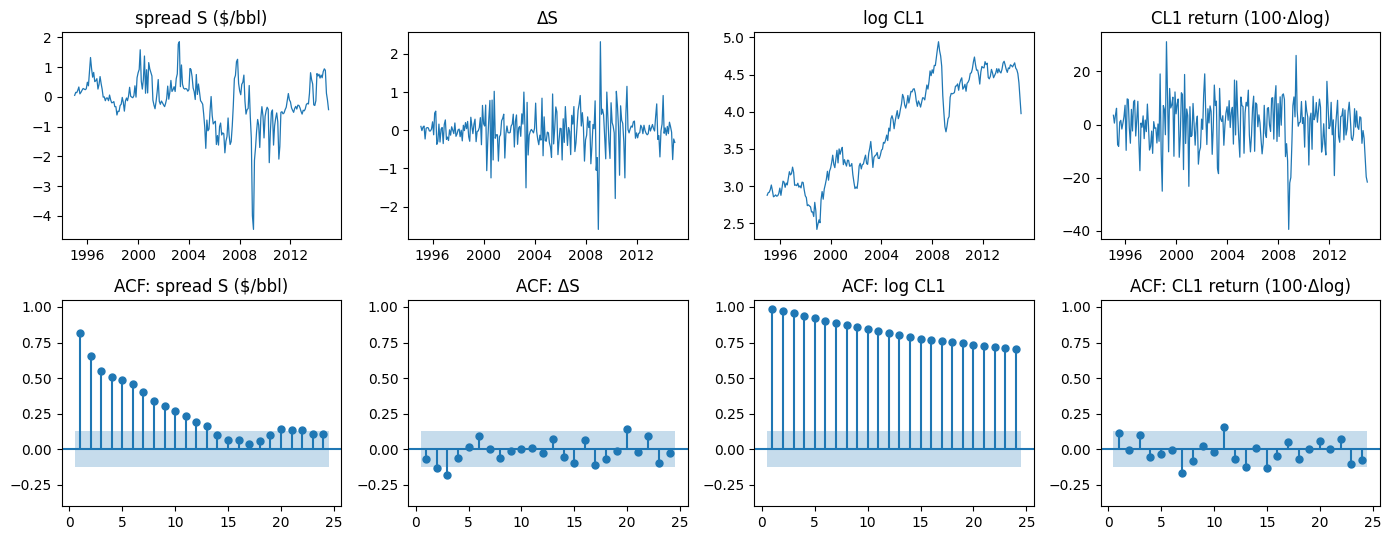

In [15]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
pre_m = m.loc[:PRE_TEST_END]
S_pre = pre_m["cl1"] - pre_m["cl2"]
panels = {"spread S ($/bbl)": S_pre, "ΔS": S_pre.diff(),
          "log CL1": np.log(pre_m["cl1"]), "CL1 return (100·Δlog)": 100 * np.log(pre_m["cl1"]).diff()}
for j, (title, x) in enumerate(panels.items()):
    axes[0, j].plot(x.index, x.values, lw=0.9)
    axes[0, j].set_title(title)
    plot_acf(x.dropna(), lags=24, ax=axes[1, j], bartlett_confint=False, zero=False, title=f"ACF: {title}")
    axes[1, j].set_ylim(-0.4, 1.05)
fig.tight_layout(); fig.savefig(RESULTS / "stationarity_acf.png", dpi=300); plt.show()

### 3.3 Spread: structural break check
Before 2015 both ADF and KPSS reject for the spread. The ACF dies out within a year and the full sample is clearly stationary, which points to a break rather than a unit root. Zivot–Andrews (H0 unit root, one break in the level chosen from the data) checks this directly.

In [16]:
za = zivot_andrews(S_pre.dropna(), regression="c", autolag="BIC", maxlag=12)
print(f"Zivot-Andrews: stat {za[0]:.2f}, 5% critical value {za[2]['5%']:.2f}, p {za[1]:.3f}, "
      f"break at {S_pre.dropna().index[za[4]]:%b %Y}")
print("Rejects unit root with a break:" if za[0] < za[2]["5%"] else "Does not reject:", za[0] < za[2]["5%"])

Zivot-Andrews: stat -6.08, 5% critical value -4.81, p 0.001, break at Sep 2004
Rejects unit root with a break: True


### 3.4 Release lags
Market prices (CL1, CL2, crack, BDI, equities, dollar, VIX) are known at the month-end close and used in their own month. Macro and industry data (IP, CPI, production, inventories, rigs, positioning, gasoline) are published the following month, so row $t$ holds month $t-1$. Treasury yields are dated one month early in the workbook and are lagged one month too. The final model uses only CL1 and CL2, so it needs no release lag.

### 3.5 Spot-check: five month-ends against the raw workbook

In [17]:
def by_month(sheet):
    f = pd.read_excel(RAW, sheet_name=sheet).dropna(subset=["Date"])
    return f.set_index(f["Date"].dt.to_period("M"))


ind_raw, mac_raw = by_month("Industry_M"), by_month("Macro_M")
SPOT = pd.to_datetime(["2008-09-30", "2014-11-30", "2020-04-30", "2022-02-28", "2024-06-30"])
spot = pd.DataFrame([{
    "raw row date": ind_raw.loc[d.to_period("M"), "Date"].date(),
    "raw CL1": ind_raw.loc[d.to_period("M"), "CL1"], "clean CL1": m.loc[d, "cl1"],
    "raw CL2": ind_raw.loc[d.to_period("M"), "CL2"], "clean CL2": m.loc[d, "cl2"],
    "spread": m.loc[d, "cl1"] - m.loc[d, "cl2"],
    "raw IP, month t": mac_raw.loc[d.to_period("M"), "IndustrialProduction Index"],
    "raw IP, month t-1": mac_raw.loc[d.to_period("M") - 1, "IndustrialProduction Index"],
    "clean IP at t": m.loc[d, "ip_index"],
} for d in SPOT], index=SPOT.strftime("%Y-%m-%d"))

assert np.allclose(spot["raw CL1"], spot["clean CL1"]) and np.allclose(spot["raw CL2"], spot["clean CL2"])
assert np.allclose(spot["raw IP, month t-1"], spot["clean IP at t"]), "IP release lag not applied"
spot.T

,2008-09-30,2014-11-30,2020-04-30,2022-02-28,2024-06-30
raw row date,2008-09-30,2014-11-28,2020-04-30,2022-02-28,2024-06-28
raw CL1,100.640,66.150,18.840,95.720,81.540
clean CL1,100.640,66.150,18.840,95.720,81.540
raw CL2,100.260,66.260,21.850,93.500,80.640
clean CL2,100.260,66.260,21.850,93.500,80.640
spread,0.380,-0.110,-3.010,2.220,0.900
"raw IP, month t",93.558,103.598,84.681,101.846,103.994
"raw IP, month t-1",97.849,102.961,97.606,101.215,103.328
clean IP at t,97.849,102.961,97.606,101.215,103.328


CL1 and CL2 equal the raw last-trading-day prices; the raw row date is the last trading day, the clean date the calendar month-end. IP in the clean row for month $t$ equals the raw value for month $t-1$. The −37.63 settlement on 20 April 2020 is not a month-end: the April 2020 row uses 30 April.